
# AI-Powered Customer Churn Prediction & Retention Intelligence

### Machine Learning | Predictive Analytics | Explainable AI | Business Intelligence

## 1. Project Overview

This project develops an intelligent machine learning system to predict customer churn and identify customers who are likely to discontinue a company's services.

The system analyses customer demographics, account information, subscription patterns and service usage to identify factors associated with customer churn.

It combines predictive modelling, explainable AI and business analytics to support data-driven customer retention strategies.

## 2. Project Objectives

- Analyse customer behaviour and churn patterns.
- Perform exploratory data analysis.
- Clean and preprocess customer data.
- Develop meaningful predictive features.
- Train and compare machine learning models.
- Evaluate model performance using appropriate metrics.
- Interpret predictions using Explainable AI.
- Identify customers with high churn risk.
- Analyse potential revenue exposure.
- Recommend data-driven retention strategies.

## 3. Technologies Used

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- XGBoost
- SHAP
- Streamlit

## 4. Dataset

IBM Telco Customer Churn Dataset.

The dataset contains customer demographics, account information, subscribed services and churn status.

## 5. Project Scope

This project demonstrates an end-to-end data science workflow, from data exploration and preprocessing to machine learning, model interpretation and business recommendations.

The project is intended for educational and portfolio purposes. It does not represent actual customer records or company data.

## 6. Expected Outcome

A predictive analytics solution that identifies churn patterns, estimates customer churn risk, explains important prediction factors and supports customer retention decision-making.


In [1]:

# Cell 2: Dataset Loading and Inspection

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Download and load dataset directly
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

# Display dataset information
print("Dataset successfully loaded!")
print("Number of customer records:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display first five records
display(df.head())

# Display column names
print("\nDataset Columns:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()


Dataset successfully loaded!
Number of customer records: 7043
Number of columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineS

Customer Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


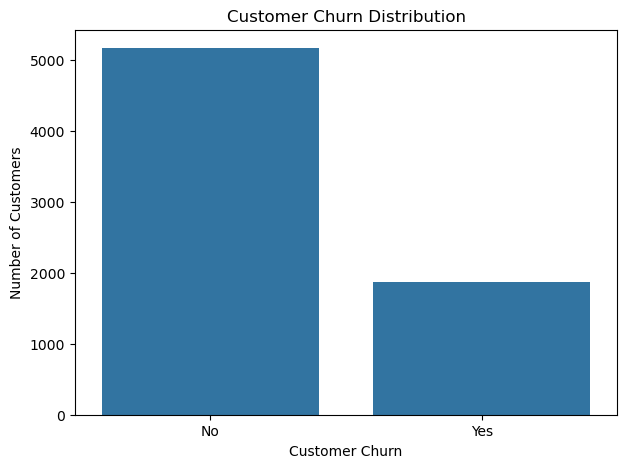

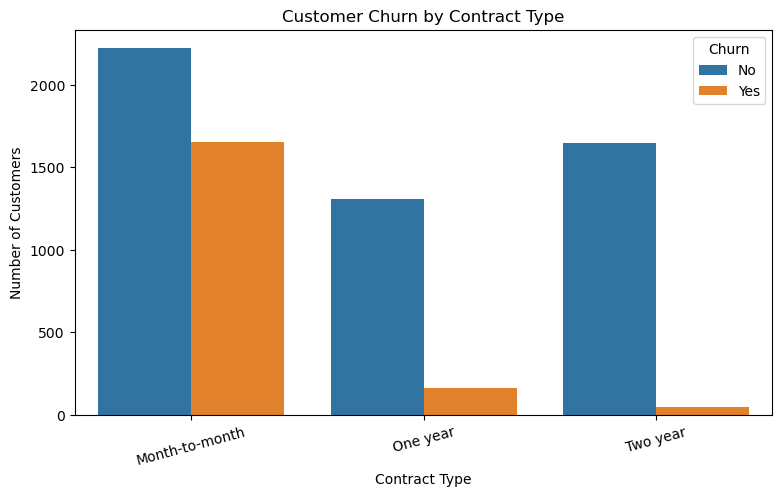

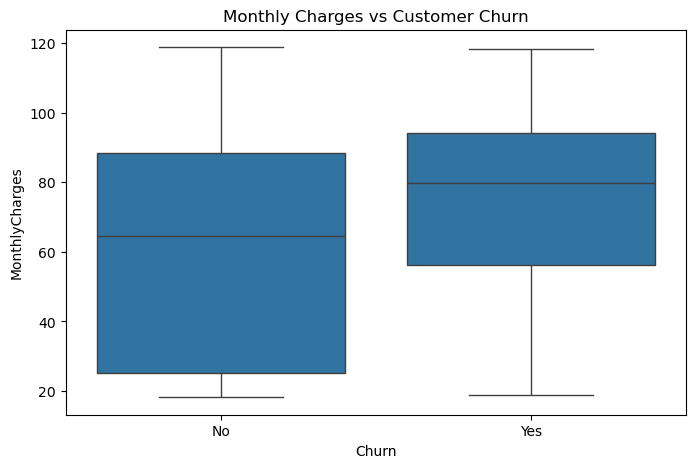

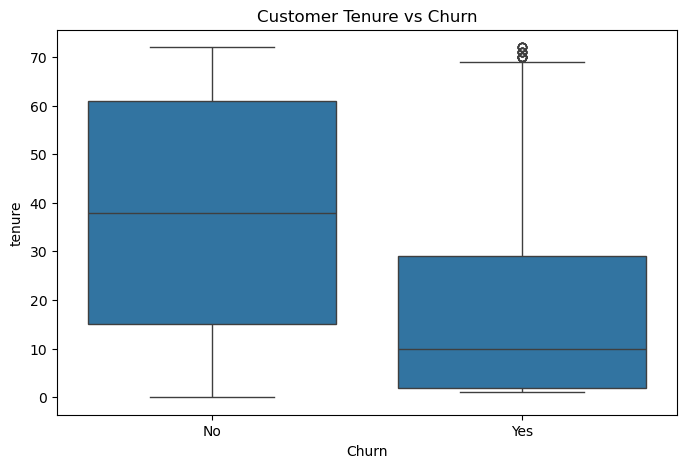

In [2]:

# Cell 3: Exploratory Data Analysis

# 1. Check churn distribution
print("Customer Churn Distribution:")
print(df["Churn"].value_counts())

# 2. Calculate churn percentages
print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

# 3. Visualize churn distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")
plt.show()

# 4. Churn by contract type
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

# 5. Monthly charges by churn status
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Customer Churn")
plt.show()

# 6. Tenure by churn status
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Customer Tenure vs Churn")
plt.show()


In [3]:

# Cell 4: Data Preprocessing

# Create a working copy
data = df.copy()

# Remove customer ID because it does not help predict churn
data.drop("customerID", axis=1, inplace=True)

# Convert TotalCharges into numeric format
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"], errors="coerce"
)

# Check missing values
print("Missing values before cleaning:")
print(data.isnull().sum().sum())

# Handle missing values
data["TotalCharges"] = data["TotalCharges"].fillna(
    data["TotalCharges"].median()
)

# Convert target variable into binary values
data["Churn"] = data["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Separate numerical and categorical columns
categorical_columns = data.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_columns = data.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Encode categorical variables
data = pd.get_dummies(
    data,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("\nData preprocessing completed!")
print("Final dataset shape:", data.shape)
print("Missing values after cleaning:", data.isnull().sum().sum())

display(data.head())


Missing values before cleaning:
11

Data preprocessing completed!
Final dataset shape: (7043, 31)
Missing values after cleaning: 0


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


In [4]:

# Cell 5: Feature Engineering

# Create a working copy
data_fe = data.copy()

# 1. Customer tenure groups
data_fe["TenureGroup"] = pd.cut(
    data_fe["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["New", "Short-Term", "Medium-Term", "Long-Term"]
)

# 2. Monthly charge categories
data_fe["ChargeCategory"] = pd.cut(
    data_fe["MonthlyCharges"],
    bins=[0, 35, 70, 120],
    labels=["Low", "Medium", "High"]
)

# 3. Average monthly spending
data_fe["AverageMonthlySpending"] = (
    data_fe["TotalCharges"] /
    data_fe["tenure"].replace(0, np.nan)
).fillna(data_fe["MonthlyCharges"])

# 4. Count subscribed services
service_columns = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

data_fe["ServiceCount"] = (
    df[service_columns]
    .apply(lambda row: sum(value == "Yes" for value in row), axis=1)
)

# 5. Long-term contract indicator
data_fe["LongTermContract"] = (
    df["Contract"] != "Month-to-month"
).astype(int)

# Encode newly created categorical features
data_fe = pd.get_dummies(
    data_fe,
    columns=["TenureGroup", "ChargeCategory"],
    drop_first=True,
    dtype=int
)

print("Feature engineering completed!")
print("Original dataset shape:", data.shape)
print("Enhanced dataset shape:", data_fe.shape)

print("\nNew engineered features:")
print([
    "TenureGroup",
    "ChargeCategory",
    "AverageMonthlySpending",
    "ServiceCount",
    "LongTermContract"
])

display(data_fe.head())


Feature engineering completed!
Original dataset shape: (7043, 31)
Enhanced dataset shape: (7043, 39)

New engineered features:
['TenureGroup', 'ChargeCategory', 'AverageMonthlySpending', 'ServiceCount', 'LongTermContract']


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,PaymentMethod_Electronic check,PaymentMethod_Mailed check,AverageMonthlySpending,ServiceCount,LongTermContract,TenureGroup_Short-Term,TenureGroup_Medium-Term,TenureGroup_Long-Term,ChargeCategory_Medium,ChargeCategory_High
0,0,1,29.85,29.85,0,0,1,0,0,1,...,1,0,29.850000,1,0,0,0,0,0,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,1,55.573529,3,1,0,1,0,1,0
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,1,54.075000,3,0,0,0,0,1,0
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,40.905556,3,1,0,1,0,1,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,1,0,75.825000,1,0,0,0,0,0,1


In [5]:

# Cell 6: Machine Learning Model Training

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Separate features and target
X = data_fe.drop("Churn", axis=1)
y = data_fe["Churn"]

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Define machine learning models
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        min_samples_split=5
    )
}

# Add XGBoost if installed
try:
    from xgboost import XGBClassifier

    models["XGBoost"] = XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    )

except ImportError:
    print("XGBoost is not installed. Using Gradient Boosting instead.")

    from sklearn.ensemble import GradientBoostingClassifier

    models["Gradient Boosting"] = GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )

# Train all models
for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    print(f"{name} trained successfully!")
    print(f"Test accuracy: {accuracy_score(y_test, predictions):.4f}")
    print("-" * 40)

print("Model training completed!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Models trained:", len(models))


XGBoost is not installed. Using Gradient Boosting instead.
Logistic Regression trained successfully!
Test accuracy: 0.7346
----------------------------------------
Random Forest trained successfully!
Test accuracy: 0.7793
----------------------------------------
Gradient Boosting trained successfully!
Test accuracy: 0.8027
----------------------------------------
Model training completed!
Training records: 5634
Testing records: 1409
Models trained: 3


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7346,0.5000,0.7941,0.6136,0.8414
1,Random Forest,0.7793,0.5849,0.5802,0.5826,0.8329
2,Gradient Boosting,0.8027,0.6702,0.5053,0.5762,0.8458



Best model based on ROC-AUC: Gradient Boosting

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.67      0.51      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



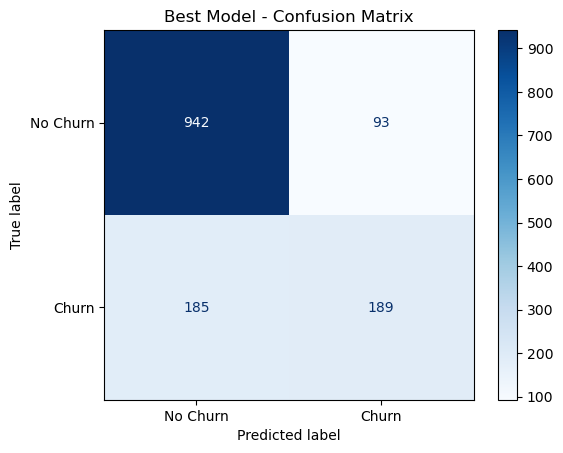

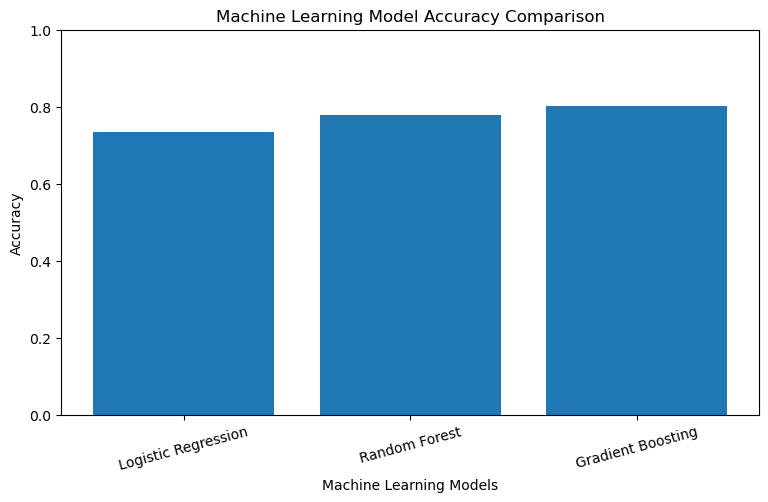

In [6]:

# Cell 7: Model Evaluation and Comparison

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import pandas as pd

results = []

# Evaluate every trained model
for name, model in models.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

# Create comparison table
results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

# Identify the model with highest ROC-AUC
best_model_name = results_df.loc[
    results_df["ROC-AUC"].idxmax(), "Model"
]

best_model = models[best_model_name]

print("\nBest model based on ROC-AUC:", best_model_name)

# Detailed classification report
best_predictions = best_model.predict(X_test)

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_predictions,
    target_names=["No Churn", "Churn"]
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Best Model - Confusion Matrix")
plt.show()

# Model accuracy comparison
plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()


In [9]:

# Cell 8: Model Optimisation and Hyperparameter Tuning

from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold
)
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import numpy as np

# Split existing training data into training and validation sets
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Define hyperparameter search space
param_grid = {
    "n_estimators": [100, 150, 200, 250],
    "learning_rate": [0.03, 0.05, 0.08, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 3, 5],
    "subsample": [0.8, 0.9, 1.0]
}

# Cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Randomized hyperparameter tuning
search = RandomizedSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_distributions=param_grid,
    n_iter=12,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

search.fit(X_subtrain, y_subtrain)

print("Best parameters:")
print(search.best_params_)

# Find an improved prediction threshold using validation data
tuned_model = search.best_estimator_
validation_probabilities = tuned_model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.20, 0.71, 0.02)

threshold_results = []

for threshold in thresholds:
    validation_predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "F1 Score": f1_score(
            y_val, validation_predictions
        ),
        "Recall": recall_score(
            y_val, validation_predictions
        )
    })

threshold_df = pd.DataFrame(threshold_results)

best_threshold = threshold_df.loc[
    threshold_df["F1 Score"].idxmax(),
    "Threshold"
]

# Refit tuned model on the full training dataset
optimized_model = search.best_estimator_
optimized_model.fit(X_train, y_train)

# Evaluate once on the test dataset
test_probabilities = optimized_model.predict_proba(X_test)[:, 1]

optimized_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("\nOPTIMISED MODEL RESULTS")
print("Selected threshold:", round(best_threshold, 2))
print("Accuracy:", round(
    accuracy_score(y_test, optimized_predictions), 4
))
print("Precision:", round(
    precision_score(y_test, optimized_predictions), 4
))
print("Recall:", round(
    recall_score(y_test, optimized_predictions), 4
))
print("F1 Score:", round(
    f1_score(y_test, optimized_predictions), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, test_probabilities), 4
))

# Save optimised model for later cells
models["Optimised Gradient Boosting"] = optimized_model

print("\nModel optimisation completed!")


Best parameters:
{'subsample': 0.8, 'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 2, 'learning_rate': 0.05}

OPTIMISED MODEL RESULTS
Selected threshold: 0.38
Accuracy: 0.7892
Precision: 0.5873
Recall: 0.6925
F1 Score: 0.6356
ROC-AUC: 0.8466

Model optimisation completed!


VALIDATION THRESHOLD COMPARISON


,Threshold,Accuracy,Precision,Recall,F1 Score,Balanced Accuracy
0,0.25,0.7418,0.5085,0.7960,0.6206,0.7591
1,0.30,0.7728,0.5531,0.7492,0.6364,0.7653
2,0.35,0.7959,0.5977,0.7057,0.6472,0.7671
3,0.40,0.8092,0.6400,0.6421,0.6411,0.7559
4,0.45,0.8154,0.6770,0.5819,0.6259,0.7408
5,0.50,0.8137,0.7070,0.5084,0.5914,0.7161
6,0.55,0.8075,0.7356,0.4281,0.5412,0.6863
7,0.60,0.7977,0.7518,0.3545,0.4818,0.6561
8,0.65,0.7835,0.7570,0.2709,0.3990,0.6198
9,0.70,0.7755,0.7805,0.2140,0.3360,0.5962


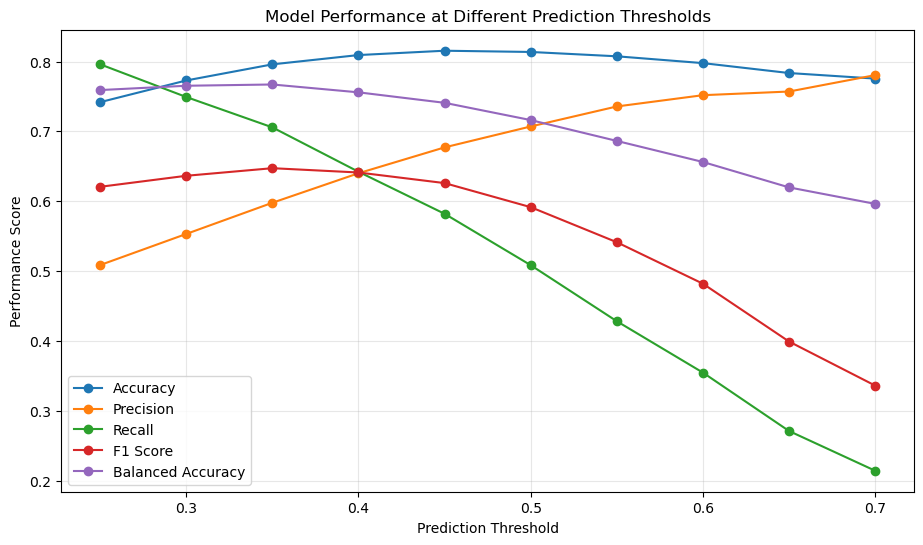

In [10]:

# Cell 8A: Balanced Threshold Comparison

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

threshold_results = []

# Test different thresholds using validation data
for threshold in np.arange(0.25, 0.71, 0.05):

    predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1 Score": f1_score(y_val, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, predictions
        )
    })

# Create comparison table
threshold_comparison = pd.DataFrame(threshold_results)

print("VALIDATION THRESHOLD COMPARISON")
display(threshold_comparison.round(4))

# Visualise the metric trade-offs
plt.figure(figsize=(11, 6))

for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "Balanced Accuracy"
]:
    plt.plot(
        threshold_comparison["Threshold"],
        threshold_comparison[metric],
        marker="o",
        label=metric
    )

plt.title("Model Performance at Different Prediction Thresholds")
plt.xlabel("Prediction Threshold")
plt.ylabel("Performance Score")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [11]:

# Balanced Threshold Evaluation

selected_threshold = 0.35

# Predict using the optimised model
test_probabilities = optimized_model.predict_proba(X_test)[:, 1]

final_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

# Calculate performance metrics
print("BALANCED MODEL PERFORMANCE")
print("--------------------------------")

print("Selected Threshold:", selected_threshold)

print("Accuracy:",
      round(accuracy_score(y_test, final_predictions), 4))

print("Precision:",
      round(precision_score(y_test, final_predictions), 4))

print("Recall:",
      round(recall_score(y_test, final_predictions), 4))

print("F1 Score:",
      round(f1_score(y_test, final_predictions), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, test_probabilities), 4))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, final_predictions), 4))

print("\nFinal evaluation completed!")


BALANCED MODEL PERFORMANCE
--------------------------------
Selected Threshold: 0.35
Accuracy: 0.7828
Precision: 0.5714
Recall: 0.7273
F1 Score: 0.64
ROC-AUC: 0.8466
Balanced Accuracy: 0.7651

Final evaluation completed!


In [13]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


SHAP analysis completed!
Customers analysed: 200


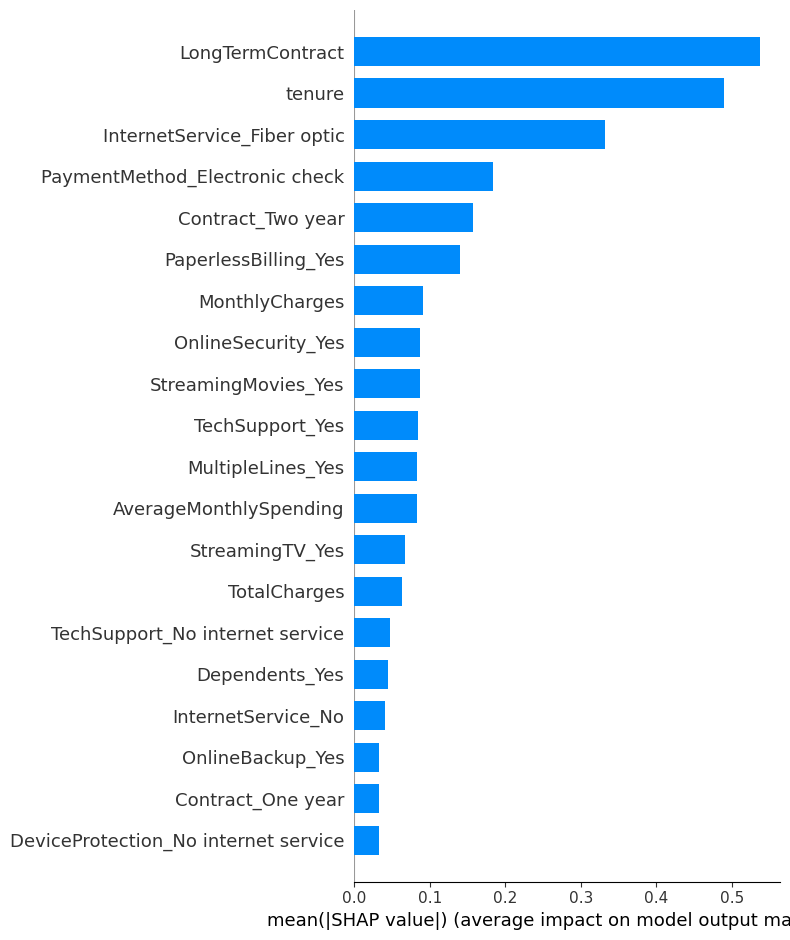

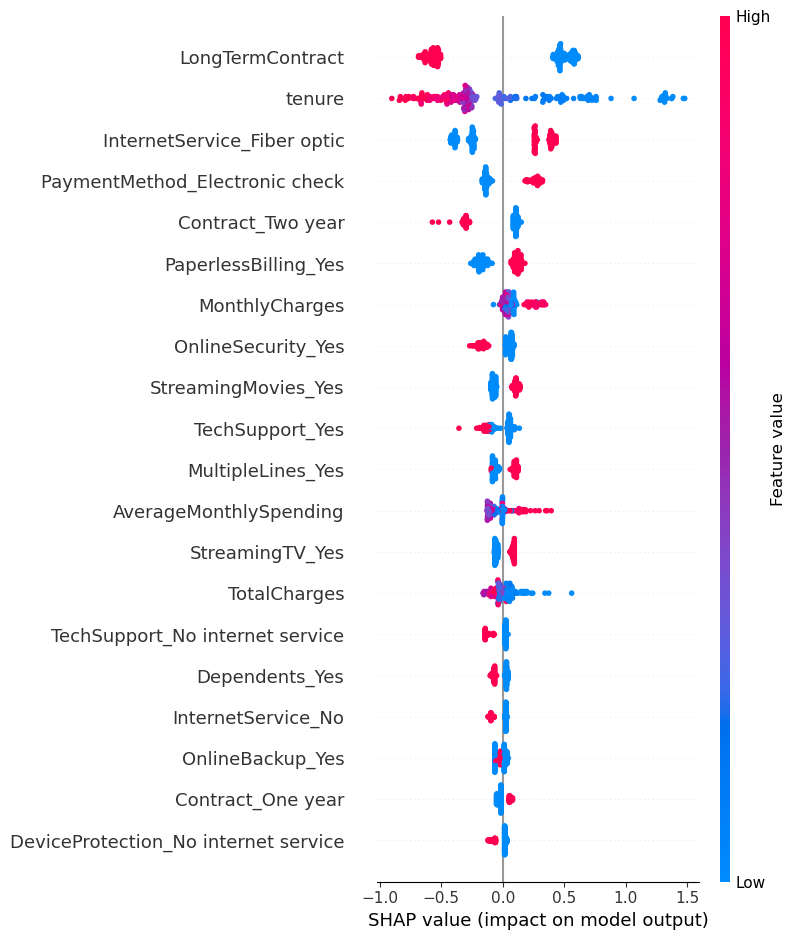


TOP 10 CHURN INFLUENCING FEATURES


,Feature,Mean Absolute SHAP
32,LongTermContract,0.5370
1,tenure,0.4897
10,InternetService_Fiber optic,0.3324
28,PaymentMethod_Electronic check,0.1843
25,Contract_Two year,0.1568
26,PaperlessBilling_Yes,0.1406
2,MonthlyCharges,0.0914
13,OnlineSecurity_Yes,0.0877
23,StreamingMovies_Yes,0.0871
19,TechSupport_Yes,0.0840


In [14]:

# Cell 9: Explainable AI using SHAP

import shap
import matplotlib.pyplot as plt
import pandas as pd

# Select a sample of test customers
X_explain = X_test.sample(
    n=min(200, len(X_test)),
    random_state=42
)

# Create SHAP explainer for the optimised model
explainer = shap.TreeExplainer(optimized_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_explain)

# Handle binary classification output
if isinstance(shap_values, list):
    churn_shap_values = shap_values[1]
elif len(shap_values.shape) == 3:
    churn_shap_values = shap_values[:, :, 1]
else:
    churn_shap_values = shap_values

print("SHAP analysis completed!")
print("Customers analysed:", len(X_explain))

# Global feature importance
shap.summary_plot(
    churn_shap_values,
    X_explain,
    plot_type="bar",
    show=True
)

# Detailed SHAP summary
shap.summary_plot(
    churn_shap_values,
    X_explain,
    show=True
)

# Display the top 10 influential features
feature_importance = pd.DataFrame({
    "Feature": X_explain.columns,
    "Mean Absolute SHAP": abs(
        churn_shap_values
    ).mean(axis=0)
})

feature_importance = feature_importance.sort_values(
    by="Mean Absolute SHAP",
    ascending=False
)

print("\nTOP 10 CHURN INFLUENCING FEATURES")
display(feature_importance.head(10).round(4))


CUSTOMER RETENTION ANALYSIS
--------------------------------
Total customers analysed: 1409

Predicted churn customers: 476

Risk category distribution:


,Customers
Risk Category,
Low Risk,933
Medium Risk,338
High Risk,138



Estimated monthly revenue exposure: $ 36447.05

CONTRACT-WISE CHURN ANALYSIS


,Contract,Total_Customers,Predicted_Churn,Average_Monthly_Charges,Predicted_Churn_Rate
0,Month-to-month,773,472,66.01,61.06
1,One year,300,4,63.29,1.33
2,Two year,336,0,60.37,0.00


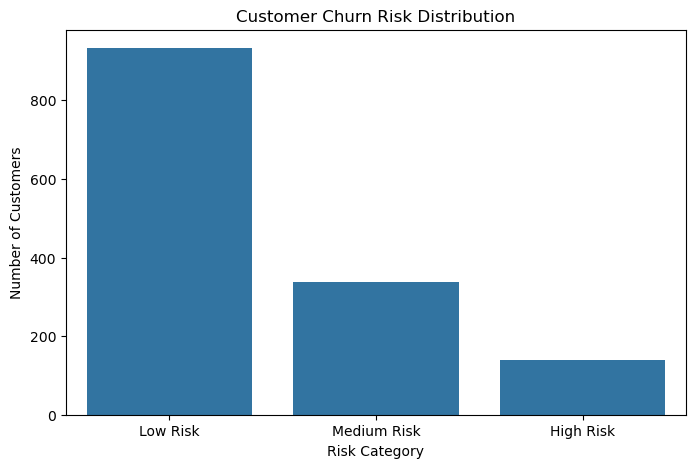

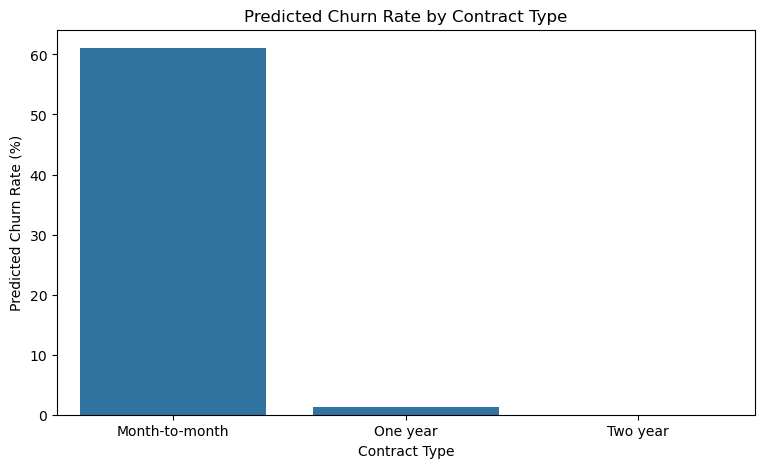


TOP HIGH-RISK CUSTOMER EXAMPLES


,customerID,tenure,Contract,MonthlyCharges,TotalCharges,Actual_Churn,Churn_Probability,Predicted_Churn,Risk_Category,Monthly_Revenue_Exposure
3380,5178-LMXOP,1,Month-to-month,95.10,95.1,1,0.920429,1,High Risk,95.10
6866,0295-PPHDO,1,Month-to-month,95.45,95.45,1,0.903775,1,High Risk,95.45
4585,1069-XAIEM,1,Month-to-month,85.05,85.05,1,0.895548,1,High Risk,85.05
6748,6230-BSUXY,1,Month-to-month,85.00,85,1,0.877807,1,High Risk,85.00
6623,9248-OJYKK,1,Month-to-month,76.45,76.45,1,0.877163,1,High Risk,76.45
2246,7181-BQYBV,1,Month-to-month,102.45,102.45,1,0.871306,1,High Risk,102.45
642,0970-ETWGE,1,Month-to-month,89.55,89.55,1,0.858434,1,High Risk,89.55
2397,3722-WPXTK,1,Month-to-month,88.35,88.35,1,0.856229,1,High Risk,88.35
6365,8884-ADFVN,7,Month-to-month,101.95,700.85,1,0.852549,1,High Risk,101.95
2464,2609-IAICY,1,Month-to-month,77.15,77.15,1,0.850883,1,High Risk,77.15



Customer retention analysis completed!


In [15]:

# Cell 10: Customer Retention Intelligence

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create customer-level prediction results
retention_analysis = df.loc[X_test.index, [
    "customerID",
    "tenure",
    "Contract",
    "MonthlyCharges",
    "TotalCharges"
]].copy()

retention_analysis["Actual_Churn"] = y_test
retention_analysis["Churn_Probability"] = test_probabilities
retention_analysis["Predicted_Churn"] = final_predictions

# 2. Assign customer risk categories
retention_analysis["Risk_Category"] = pd.cut(
    retention_analysis["Churn_Probability"],
    bins=[-0.001, 0.35, 0.65, 1.001],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

# 3. Estimate monthly revenue exposure
retention_analysis["Monthly_Revenue_Exposure"] = np.where(
    retention_analysis["Predicted_Churn"] == 1,
    retention_analysis["MonthlyCharges"],
    0
)

print("CUSTOMER RETENTION ANALYSIS")
print("--------------------------------")

print("Total customers analysed:",
      len(retention_analysis))

print("\nPredicted churn customers:",
      int(retention_analysis["Predicted_Churn"].sum()))

print("\nRisk category distribution:")
display(
    retention_analysis["Risk_Category"]
    .value_counts()
    .rename_axis("Risk Category")
    .to_frame("Customers")
)

# 4. Estimate monthly revenue exposure
revenue_exposure = (
    retention_analysis["Monthly_Revenue_Exposure"].sum()
)

print("\nEstimated monthly revenue exposure: $",
      round(revenue_exposure, 2))

# 5. Analyse churn by contract type
contract_analysis = retention_analysis.groupby(
    "Contract",
    observed=False
).agg(
    Total_Customers=("customerID", "count"),
    Predicted_Churn=("Predicted_Churn", "sum"),
    Average_Monthly_Charges=("MonthlyCharges", "mean")
).reset_index()

contract_analysis["Predicted_Churn_Rate"] = (
    contract_analysis["Predicted_Churn"] /
    contract_analysis["Total_Customers"] * 100
)

print("\nCONTRACT-WISE CHURN ANALYSIS")
display(contract_analysis.round(2))

# 6. Visualise customer risk distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=retention_analysis,
    x="Risk_Category",
    order=["Low Risk", "Medium Risk", "High Risk"]
)

plt.title("Customer Churn Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")
plt.show()

# 7. Visualise predicted churn by contract
plt.figure(figsize=(9, 5))

sns.barplot(
    data=contract_analysis,
    x="Contract",
    y="Predicted_Churn_Rate"
)

plt.title("Predicted Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Predicted Churn Rate (%)")
plt.show()

# 8. Display high-risk customer examples
high_risk_customers = retention_analysis[
    retention_analysis["Risk_Category"] == "High Risk"
].sort_values(
    "Churn_Probability",
    ascending=False
)

print("\nTOP HIGH-RISK CUSTOMER EXAMPLES")
display(high_risk_customers.head(10))

print("\nCustomer retention analysis completed!")



# FINAL PROJECT REPORT
# AI-Powered Customer Churn Prediction & Retention Intelligence

## 1. Executive Summary

This project develops a machine learning-based customer churn prediction and retention intelligence system using the IBM Telco Customer Churn public dataset.

The objective is to identify customers who are likely to discontinue their services by analysing customer demographics, subscription patterns, billing information and service usage.

The project combines exploratory data analysis, feature engineering, predictive modelling, hyperparameter optimisation, explainable artificial intelligence and customer risk analysis.

The system demonstrates how machine learning can support data-driven customer retention decisions.

## 2. Project Objectives

- Analyse customer behaviour and churn patterns.
- Perform exploratory data analysis and data preprocessing.
- Engineer meaningful predictive features.
- Develop and compare multiple machine learning models.
- Optimise model hyperparameters using cross-validation.
- Evaluate models using multiple performance metrics.
- Apply Explainable AI to interpret model predictions.
- Identify customers with different levels of churn risk.
- Estimate potential monthly revenue exposure.
- Develop actionable customer retention recommendations.

## 3. Dataset Description

Dataset: IBM Telco Customer Churn public sample dataset.

Dataset characteristics:
- Total customer records: 7,043
- Original attributes: 21
- Target variable: Churn
- Target classes: Yes and No

Important attributes include:
- Customer tenure
- Monthly charges
- Total charges
- Contract type
- Payment method
- Internet service
- Customer subscribed services
- Churn status

The target variable was encoded as:
- No = 0
- Yes = 1

## 4. Technologies and Tools

Programming Language:
- Python

Data Analysis:
- Pandas
- NumPy

Data Visualisation:
- Matplotlib
- Seaborn

Machine Learning:
- Scikit-learn
- Logistic Regression
- Random Forest
- Gradient Boosting

Explainable AI:
- SHAP

Deployment Technology:
- Streamlit (planned future extension)

Development Environment:
- Anaconda Navigator
- Jupyter Notebook

## 5. Project Methodology

The project follows an end-to-end machine learning workflow:

1. Dataset loading and inspection.
2. Exploratory data analysis.
3. Data cleaning and preprocessing.
4. Categorical variable encoding.
5. Feature engineering.
6. Training and testing data separation.
7. Machine learning model training.
8. Model evaluation and comparison.
9. Hyperparameter tuning.
10. Prediction threshold optimisation.
11. SHAP-based model interpretation.
12. Customer risk categorisation.
13. Revenue exposure estimation.
14. Business recommendations.

## 6. Feature Engineering

Additional predictive features were developed:

- TenureGroup: Categorises customers based on relationship duration.
- ChargeCategory: Groups customers by monthly charges.
- AverageMonthlySpending: Estimates average monthly spending.
- ServiceCount: Counts the number of subscribed services.
- LongTermContract: Identifies customers with longer-term contracts.

These features were created to explore additional patterns associated with customer churn.

## 7. Machine Learning Models

Three machine learning algorithms were trained and compared.

### Initial Model Performance

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 73.46% | 50.00% | 79.41% | 61.36% | 84.14% |
| Random Forest | 77.93% | 58.49% | 58.02% | 58.26% | 83.29% |
| Gradient Boosting | 80.27% | 67.02% | 50.53% | 57.62% | 84.58% |

Gradient Boosting achieved the highest initial accuracy and ROC-AUC among the three models.

## 8. Model Optimisation

Hyperparameter tuning was performed using RandomizedSearchCV and stratified cross-validation.

The prediction threshold was also adjusted to investigate the trade-off between precision and recall.

### Optimised Model Performance

At the selected candidate threshold of 0.35:

- Accuracy: 78.28%
- Precision: 57.14%
- Recall: 72.73%
- F1-score: 64.00%
- ROC-AUC: 84.66%
- Balanced Accuracy: 76.51%

The optimised model improved recall and F1-score compared with the initial Gradient Boosting model, while accuracy and precision decreased.

This demonstrates the trade-off between identifying potential churners and avoiding false positive predictions.

The 0.35 threshold is a candidate for a retention-focused approach, not a universally optimal threshold.

## 9. Explainable AI — SHAP Analysis

SHAP was implemented to interpret the features influencing the optimised Gradient Boosting model.

The analysis identified influential features including:

- LongTermContract
- Customer tenure
- InternetService_Fiber optic
- PaymentMethod_Electronic check
- Contract_Two year
- PaperlessBilling_Yes
- MonthlyCharges
- OnlineSecurity_Yes

These features help explain the patterns used by the model when generating churn predictions.

SHAP provides model explanations and feature associations. It does not establish causal relationships.

## 10. Customer Retention Intelligence

The customer retention analysis evaluated 1,409 test records.

### Customer Risk Distribution

- Low Risk: 933 customers
- Medium Risk: 338 customers
- High Risk: 138 customers

The model separately identified 476 customers as potential churners using the 0.35 prediction threshold.

The risk categories use separate probability boundaries:
- Low Risk: Probability below 0.35
- Medium Risk: Probability from 0.35 to 0.65
- High Risk: Probability above 0.65

The project also analysed:
- Predicted churn across contract types.
- Average monthly customer charges.
- Potential monthly revenue exposure.
- High-risk customer examples.

Revenue exposure is an illustrative estimate based on the monthly charges of customers predicted to churn. It does not represent confirmed lost revenue or guaranteed recoverable revenue.

## 11. Business Insights and Recommendations

The analysis can support further investigation into the following retention strategies:

### Customer Onboarding
Investigate whether new customers require additional onboarding support.

### Contract Management
Explore suitable longer-term contract options and customer retention strategies.

### Pricing and Billing
Investigate whether pricing, billing preferences and perceived service value are associated with churn.

### Customer Support
Identify opportunities to improve customer support and service experience.

### Targeted Retention
Prioritise appropriate outreach to customers with higher predicted churn probabilities.

These are proposed business interventions requiring further validation, not guaranteed solutions.

## 12. Model Validation and Experimental Limitations

The reported model results should be interpreted as experimental development results.

The following limitations apply:

- Hyperparameter tuning was performed using training data and cross-validation.
- Prediction threshold selection was performed using validation data.
- Test-set results were inspected during iterative model development.
- Therefore, the test set was not completely untouched throughout the development process.
- The reported performance figures should not be described as independently validated final performance.
- A fresh, previously unseen holdout dataset or appropriately designed nested cross-validation procedure is needed for independent performance validation.
- Further evaluation on new customer data would be required before real-world deployment.

## 13. Technical and Business Limitations

- Model performance depends on the dataset and its characteristics.
- The dataset represents a telecommunications business rather than a banking or wealth management institution.
- Predictions indicate statistical patterns, not certainty about future customer behaviour.
- SHAP identifies model associations, not causation.
- Revenue exposure is an estimate, not actual financial loss.
- Customer risk categories depend on selected probability thresholds.
- The model may not generalise equally well to other customer populations.
- Accuracy alone is insufficient for evaluating churn prediction performance.

## 14. Future Scope

Potential future improvements include:

- Implementing XGBoost and comparing additional boosting algorithms.
- Applying advanced feature selection techniques.
- Improving model calibration.
- Performing independent model validation.
- Exploring customer lifetime value analysis.
- Developing a Streamlit-based interactive dashboard.
- Adding individual customer prediction explanations.
- Investigating retention campaign effectiveness.
- Evaluating the model on additional customer datasets.

## 15. Final Conclusion

This project demonstrates an end-to-end machine learning workflow for customer churn prediction and retention intelligence.

By combining exploratory data analysis, feature engineering, multiple predictive algorithms, model optimisation, explainable AI and business analytics, the system demonstrates how data science can support customer retention decision-making.

The comparison of multiple performance metrics highlights the importance of balancing accuracy, precision, recall and F1-score.

The project also demonstrates the importance of transparent model evaluation, explainability and independent validation before considering deployment.

## 16. Dataset Attribution and Project Disclaimer

Dataset Source:
IBM Telco Customer Churn public sample dataset.

This is an independent educational and portfolio project. It is not affiliated with, endorsed by or representative of Morgan Stanley or any other financial institution.

The project uses a publicly available telecommunications dataset and does not use confidential company or customer records.

The analysis, model predictions and business recommendations are intended for educational and portfolio purposes only. They should not be interpreted as verified real-world outcomes, financial advice or production-ready customer decisions.
